# Audit Analytics Project: Detecting Hotel Operational Exceptions
## An NLP-Based Framework for Guest Complaint Analysis and Risk Prioritisation

## Data Collection

In [ ]:
import pandas as pd

# Load dataset
df = pd.read_csv("reviews.csv")

print("Dataset dimensions:", df.shape)
print("Number of reviews:", len(df))
print("Number of columns:", df.shape[1])

display(df.head())
df.info()

# Summary statistics
display(df.describe(include="all"))

# Missing values
print("\nMissing values:")
display(df.isnull().sum())

# Duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())


Dataset dimensions: (1628989, 17)
Number of reviews: 1628989
Number of columns: 17


,review_title,review_positive,review_negative,review_score,review_helpful_votes,guest_type,guest_country,room_nights,month,accommodation_id,accommodation_type,accommodation_country,accommodation_score,accommodation_star_rating,location_is_ski,location_is_beach,location_is_city_center
0,NaN,"Beautiful bathroom, comfortable bed.",No robes were provided. No couches in rooms.,7.0,0,Couple,Zuc,1,9,-548048990,Hotel,Australia,8.7,4.5,0,0,1
1,Fantastic location and service,Great location and easy to get to The view fr...,NaN,8.0,0,Family with children,Made,5,9,1225335718,Bed and Breakfast,South Africa,7.9,0.0,0,0,0
2,Great central location,"Central location, friendly helpful staff","No aircon, no access back to hotel from hotel ...",7.0,0,Couple,Xazas,2,12,-1296112659,ApartHotel,New Zealand,8.2,0.0,0,1,0
3,Great place in a great location,Room was very spacious and the king size bed w...,Noise from upstairs was loud and most mornings...,8.0,0,Couple,Nukeye,3,10,-2104338227,Hotel,United States of America,7.5,2.0,0,0,0
4,Fantastic find,This was perfect in every way - close to the s...,Nothing - everything was great,10.0,0,Family with children,Mejok,1,9,-42373088,Bed and Breakfast,Italy,8.5,0.0,0,0,1


<class 'pandas.DataFrame'>
RangeIndex: 1628989 entries, 0 to 1628988
Data columns (total 17 columns):
 #   Column                     Non-Null Count    Dtype  
---  ------                     --------------    -----  
 0   review_title               1097128 non-null  str    
 1   review_positive            1628981 non-null  str    
 2   review_negative            1159440 non-null  str    
 3   review_score               1628989 non-null  float64
 4   review_helpful_votes       1628989 non-null  int64  
 5   guest_type                 1628989 non-null  str    
 6   guest_country              1626791 non-null  str    
 7   room_nights                1628989 non-null  int64  
 8   month                      1628989 non-null  int64  
 9   accommodation_id           1628989 non-null  int64  
 10  accommodation_type         1628989 non-null  str    
 11  accommodation_country      1628989 non-null  str    
 12  accommodation_score        1628989 non-null  float64
 13  accommodation_star_rati

,review_title,review_positive,review_negative,review_score,review_helpful_votes,guest_type,guest_country,room_nights,month,accommodation_id,accommodation_type,accommodation_country,accommodation_score,accommodation_star_rating,location_is_ski,location_is_beach,location_is_city_center
count,1097128,1628981,1159440,1.628989e+06,1.628989e+06,1628989,1626791,1.628989e+06,1.628989e+06,1.628989e+06,1628989,1628989,1.628989e+06,1.628989e+06,1.628989e+06,1.628989e+06,1.628989e+06
unique,844148,1582370,914773,NaN,NaN,4,237,NaN,NaN,NaN,27,180,NaN,NaN,NaN,NaN,NaN
top,Excellent,Breakfast,Nothing,NaN,NaN,Couple,Mejok,NaN,NaN,NaN,Hotel,United Kingdom,NaN,NaN,NaN,NaN,NaN
freq,5339,1440,60392,NaN,NaN,700668,468088,NaN,NaN,NaN,922264,315479,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,8.871634e+00,1.217989e-01,NaN,NaN,2.583871e+00,6.618263e+00,3.079934e+06,NaN,NaN,8.384487e+00,2.382434e+00,2.865642e-02,2.530962e-01,2.537482e-01
std,NaN,NaN,NaN,1.166345e+00,5.082283e-01,NaN,NaN,2.363845e+00,3.093631e+00,1.235929e+09,NaN,NaN,7.651622e-01,1.772637e+00,1.668390e-01,4.347858e-01,4.351553e-01
min,NaN,NaN,NaN,1.000000e+00,0.000000e+00,NaN,NaN,1.000000e+00,1.000000e+00,-2.147447e+09,NaN,NaN,2.400000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,NaN,NaN,NaN,8.000000e+00,0.000000e+00,NaN,NaN,1.000000e+00,4.000000e+00,-1.056474e+09,NaN,NaN,8.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,NaN,NaN,NaN,9.000000e+00,0.000000e+00,NaN,NaN,2.000000e+00,7.000000e+00,-3.509157e+06,NaN,NaN,8.500000e+00,3.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
75%,NaN,NaN,NaN,1.000000e+01,0.000000e+00,NaN,NaN,3.000000e+00,9.000000e+00,1.076218e+09,NaN,NaN,8.900000e+00,4.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00



Missing values:


review_title                 531861
review_positive                   8
review_negative              469549
review_score                      0
review_helpful_votes              0
guest_type                        0
guest_country                  2198
room_nights                       0
month                             0
accommodation_id                  0
accommodation_type                0
accommodation_country             0
accommodation_score               0
accommodation_star_rating         0
location_is_ski                   0
location_is_beach                 0
location_is_city_center           0
dtype: int64


Duplicate rows: 236


## Data Processing

In [ ]:
# Check for duplicated positive and negative reviews
positive_counts = (
    df["review_positive"]
    .dropna()
    .value_counts()
    .reset_index()
)

positive_counts.columns = ["review_positive", "count"]

positive_counts = positive_counts[
    positive_counts["count"] > 1
]

display(positive_counts)

negative_counts = (
    df["review_negative"]
    .dropna()
    .value_counts()
    .reset_index()
)

negative_counts.columns = ["review_negative", "count"]

negative_counts = negative_counts[
    negative_counts["count"] > 1
]

display(negative_counts)

,review_positive,count
0,Breakfast,1440
1,Clean and comfortable,902
2,Room,666
3,Breakfast was good,554
4,breakfast,548
...,...,...
10691,"room, location, spa",2
10692,"Comfy beds, friendly staff",2
10693,Near motorway,2
10694,Facilities were clean,2


,review_negative,count
0,Nothing,60392
1,nothing,18010
2,Nothing.,12589
3,N&#47;A,11664
4,-,6342
...,...,...
15280,Beds weren’t that comfy,2
15281,Absolutely none.,2
15282,There wasn’t really anything that we didn’t like.,2
15283,Parking fee is very high.,2


In [3]:
# Check the number of fully duplicated rows 
print("Duplicate rows:", df.duplicated().sum())

# Remove exact duplicate rows, keeping the first occurrence
df_clean = df.drop_duplicates(keep="first").copy()

# Compare dataset sizes
print("Original dataset:", df.shape)
print("Cleaned dataset:", df_clean.shape)
print("Rows removed:", len(df) - len(df_clean))

print("Remaining duplicate rows:", df_clean.duplicated().sum())

Duplicate rows: 236
Original dataset: (1628989, 17)
Cleaned dataset: (1628753, 17)
Rows removed: 236
Remaining duplicate rows: 0


In [ ]:
# Only keep records where 'accommodation_type == hotel'
df["accommodation_type"].value_counts(dropna=False)

# Keep only hotels, regardless of capitalisation or extra spaces
df_clean = df_clean[
    df_clean["accommodation_type"]
    .str.strip()
    .str.lower()
    .eq("hotel")
    .fillna(False)
].copy()

# Check the results
print("Remaining rows:", len(df_clean))
print("Accommodation types:")
print(df_clean["accommodation_type"].value_counts(dropna=False))

Remaining rows: 922121
Accommodation types:
accommodation_type
Hotel    922121
Name: count, dtype: int64


In [ ]:
import pandas as pd
import re
import nltk

from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

text_cols = [
    "review_title",
    "review_positive",
    "review_negative"
]

for col in text_cols:
    df_clean[col] = df_clean[col].astype("string").str.strip()

# Convert empty strings to missing values
df_clean[text_cols] = df_clean[text_cols].replace("", pd.NA)

# Standardise numerical fields 
df_clean["review_score"] = pd.to_numeric(
    df_clean["review_score"], errors="coerce"
)

df_clean["room_nights"] = pd.to_numeric(
    df_clean["room_nights"], errors="coerce"
)

df_clean["month"] = pd.to_numeric(
    df_clean["month"], errors="coerce"
)

df_clean.info()

# Combine the review text
df_clean["review_text"] = (
    df_clean[["review_title", "review_positive", "review_negative"]]
    .fillna("")
    .agg(" ".join, axis=1)
    .str.strip()
)

# Remove records without any review text at all
df_clean = df_clean[
    df_clean["review_text"].str.len() > 0
].copy()

display(df_clean[[
    "review_title",
    "review_positive",
    "review_negative",
    "review_text"
]].head())

[nltk_data] Downloading package punkt to
[nltk_data]     /Users/kayeannesabater/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /Users/kayeannesabater/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/kayeannesabater/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     /Users/kayeannesabater/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     /Users/kayeannesabater/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


<class 'pandas.DataFrame'>
Index: 922121 entries, 0 to 1628988
Data columns (total 17 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   review_title               624792 non-null  string 
 1   review_positive            922115 non-null  string 
 2   review_negative            679941 non-null  string 
 3   review_score               922121 non-null  float64
 4   review_helpful_votes       922121 non-null  int64  
 5   guest_type                 922121 non-null  str    
 6   guest_country              920977 non-null  str    
 7   room_nights                922121 non-null  int64  
 8   month                      922121 non-null  int64  
 9   accommodation_id           922121 non-null  int64  
 10  accommodation_type         922121 non-null  str    
 11  accommodation_country      922121 non-null  str    
 12  accommodation_score        922121 non-null  float64
 13  accommodation_star_rating  922121 non-null  

,review_title,review_positive,review_negative,review_text
0,<NA>,"Beautiful bathroom, comfortable bed.",No robes were provided. No couches in rooms.,"Beautiful bathroom, comfortable bed. No robes ..."
3,Great place in a great location,Room was very spacious and the king size bed w...,Noise from upstairs was loud and most mornings...,Great place in a great location Room was very ...
5,<NA>,Great location. Really nice room. Good breakfast,People working at the front desk are not so ki...,Great location. Really nice room. Good breakfa...
6,<NA>,"Hotel needs a bit of tlc, clean room and good ...",<NA>,"Hotel needs a bit of tlc, clean room and good ..."
8,Perfect stay,"Can&#39;t say enough , most amazing stay , lov...",Everything was perfect.,"Perfect stay Can&#39;t say enough , most amazi..."


In [ ]:
# Normalize

def normalise_text(text):
    text = text.lower()

    # Remove HTML tags
    text = re.sub(r"<[^>]+>", " ", text)

    # Remove URLs
    text = re.sub(r"http\S+|www\.\S+", " ", text)

    # Keep alphabetic characters and spaces
    text = re.sub(r"[^a-z\s]", " ", text)

    # Remove extra whitespace
    text = re.sub(r"\s+", " ", text).strip()

    return text

df_clean["review_normalised"] = df_clean["review_text"].apply(
    normalise_text
)

display(df_clean[["review_text", "review_normalised"]].head())

,review_text,review_normalised
0,"Beautiful bathroom, comfortable bed. No robes ...",beautiful bathroom comfortable bed no robes we...
3,Great place in a great location Room was very ...,great place in a great location room was very ...
5,Great location. Really nice room. Good breakfa...,great location really nice room good breakfast...
6,"Hotel needs a bit of tlc, clean room and good ...",hotel needs a bit of tlc clean room and good v...
8,"Perfect stay Can&#39;t say enough , most amazi...",perfect stay can t say enough most amazing sta...


In [ ]:
# Tokenisation and removal of irrelevant words

stop_words = set(stopwords.words("english"))

# Preserve negation words because they are important for complaints
stop_words -= {"no", "not", "nor", "never"}

def tokenize_and_remove_stopwords(text):
    tokens = word_tokenize(text)

    # Keep alphabetic tokens with at least 2 characters
    tokens = [
        word for word in tokens
        if word.isalpha()
        and len(word) > 1
        and word not in stop_words
    ]

    return tokens

df_clean["review_tokens"] = df_clean["review_normalised"].apply(
    tokenize_and_remove_stopwords
)

display(df_clean[[
    "review_normalised",
    "review_tokens"
]].head())

,review_normalised,review_tokens
0,beautiful bathroom comfortable bed no robes we...,"[beautiful, bathroom, comfortable, bed, no, ro..."
3,great place in a great location room was very ...,"[great, place, great, location, room, spacious..."
5,great location really nice room good breakfast...,"[great, location, really, nice, room, good, br..."
6,hotel needs a bit of tlc clean room and good v...,"[hotel, needs, bit, tlc, clean, room, good, va..."
8,perfect stay can t say enough most amazing sta...,"[perfect, stay, say, enough, amazing, stay, lo..."


In [ ]:
# Lemmatise

lemmatizer = WordNetLemmatizer()

def lemmatise_tokens(tokens):
    return [
        lemmatizer.lemmatize(word)
        for word in tokens
    ]

df_clean["review_tokens_clean"] = df_clean["review_tokens"].apply(
    lemmatise_tokens
)

display(df_clean[[
    "review_text",
    "review_tokens_clean"
]].head())

,review_text,review_tokens_clean
0,"Beautiful bathroom, comfortable bed. No robes ...","[beautiful, bathroom, comfortable, bed, no, ro..."
3,Great place in a great location Room was very ...,"[great, place, great, location, room, spacious..."
5,Great location. Really nice room. Good breakfa...,"[great, location, really, nice, room, good, br..."
6,"Hotel needs a bit of tlc, clean room and good ...","[hotel, need, bit, tlc, clean, room, good, val..."
8,"Perfect stay Can&#39;t say enough , most amazi...","[perfect, stay, say, enough, amazing, stay, lo..."


In [ ]:
# Inspect processed reviews to make sure that the review meaning remains intact

# Compare original and processed text
display(df_clean[[
    "review_text",
    "review_normalised",
    "review_tokens_clean"
]].sample(10, random_state=42))

# Check missing or empty processed reviews
print(
    "Empty processed reviews:",
    df_clean["review_tokens_clean"].apply(len).eq(0).sum()
)

# Check updated dataset dimensions
print("Dataset shape:", df_clean.shape)

,review_text,review_normalised,review_tokens_clean
1419400,I got free breakfast! The buffet is really nic...,i got free breakfast the buffet is really nice...,"[got, free, breakfast, buffet, really, nice, s..."
469850,"Great location, very friendly staff, super bre...",great location very friendly staff super break...,"[great, location, friendly, staff, super, brea..."
1559535,Walking distance from the airport. Comfortable...,walking distance from the airport comfortable ...,"[walking, distance, airport, comfortable, bed,..."
535264,"Good location, but the lack of hot water made ...",good location but the lack of hot water made t...,"[good, location, lack, hot, water, made, stay,..."
1058204,We loved our stay ! -Room and bathroom were ve...,we loved our stay room and bathroom were very ...,"[loved, stay, room, bathroom, clean, comfortab..."
504181,It was ok. I don’t think it’s worth the price ...,it was ok i don t think it s worth the price w...,"[ok, think, worth, price, paid, guy, came, par..."
1458170,"In front of Luxor temple, you can see sunset f...",in front of luxor temple you can see sunset fr...,"[front, luxor, temple, see, sunset, restaurant..."
1268703,Handy stop over for airport Super convenient f...,handy stop over for airport super convenient f...,"[handy, stop, airport, super, convenient, airp..."
978938,perfect location! perfect location! The Town o...,perfect location perfect location the town of ...,"[perfect, location, perfect, location, town, f..."
1310540,"all were okay, big room, nice view",all were okay big room nice view,"[okay, big, room, nice, view]"


Empty processed reviews: 28
Dataset shape: (922116, 21)


In [ ]:
# Prep text for modelling by converting token lists back into strings

df_clean["review_processed"] = df_clean[
    "review_tokens_clean"
].apply(lambda tokens: " ".join(tokens))

display(df_clean[[
    "review_text",
    "review_processed"
]].head())

,review_text,review_processed
0,"Beautiful bathroom, comfortable bed. No robes ...",beautiful bathroom comfortable bed no robe pro...
3,Great place in a great location Room was very ...,great place great location room spacious king ...
5,Great location. Really nice room. Good breakfa...,great location really nice room good breakfast...
6,"Hotel needs a bit of tlc, clean room and good ...",hotel need bit tlc clean room good value money
8,"Perfect stay Can&#39;t say enough , most amazi...",perfect stay say enough amazing stay loved fac...


In [ ]:
# Export as csv for checking
df_clean.to_csv("hotel_reviews_cleaned.csv", index=False)

## Exploratory Data Analysis

In [ ]:
# Overview of remaining dataset

print("Dataset size:", df_clean.shape)
print("\nMissing values:")
print(df_clean.isnull().sum())

print("\nReview score summary:")
print(df_clean["review_score"].describe())

print("\nReview text length:")
df_clean["review_text_length"] = df_clean["review_text"].str.len()
print(df_clean["review_text_length"].describe())

Dataset size: (922116, 22)

Missing values:
review_title                 297324
review_positive                   1
review_negative              242175
review_score                      0
review_helpful_votes              0
guest_type                        0
guest_country                  1144
room_nights                       0
month                             0
accommodation_id                  0
accommodation_type                0
accommodation_country             0
accommodation_score               0
accommodation_star_rating         0
location_is_ski                   0
location_is_beach                 0
location_is_city_center           0
review_text                       0
review_normalised                 0
review_tokens                     0
review_tokens_clean               0
review_processed                  0
dtype: int64

Review score summary:
count    922116.000000
mean          8.751617
std           1.190698
min           1.000000
25%           8.000000
50%          

room: 807976
location: 527097
hotel: 508585
staff: 503684
great: 458384
good: 453601
breakfast: 415399
clean: 355799
stay: 307968
nice: 269421
not: 266760
comfortable: 252625
friendly: 239810
bed: 202017
helpful: 162599
excellent: 156583
would: 148106
no: 145956
restaurant: 133733
lovely: 124926


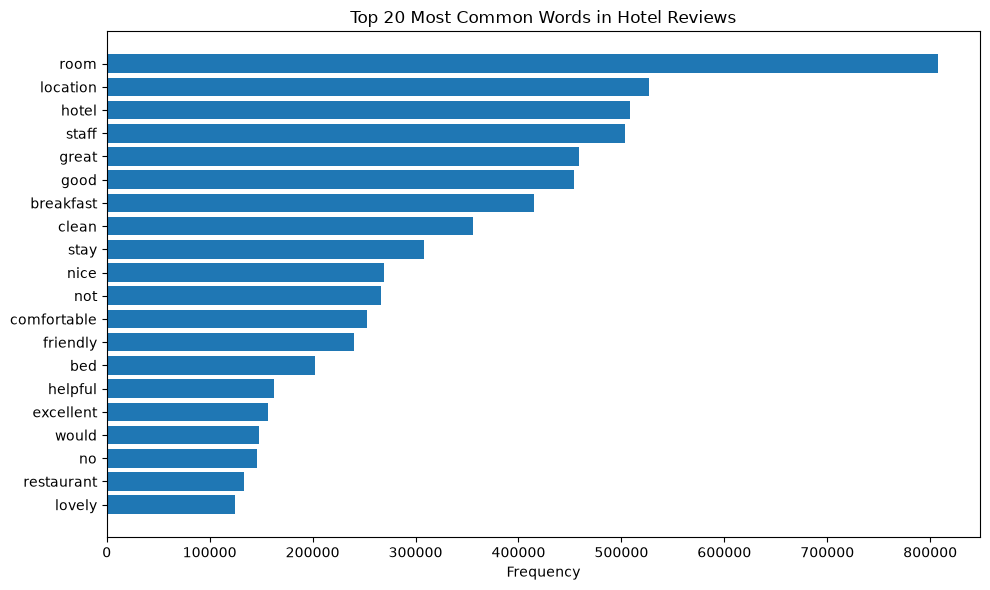

In [ ]:
# Find the most commonly occuring words
from collections import Counter
import matplotlib.pyplot as plt

# Combine all processed review text and count words
word_counts = Counter(
    " ".join(df_clean["review_processed"].dropna()).split()
)

# Display the 20 most common words
top_words = word_counts.most_common(20)

for word, count in top_words:
    print(f"{word}: {count}")

    words, counts = zip(*top_words)

plt.figure(figsize=(10, 6))
plt.barh(words[::-1], counts[::-1])
plt.xlabel("Frequency")
plt.title("Top 20 Most Common Words in Hotel Reviews")
plt.tight_layout()
plt.show()

In [ ]:
# Separate positive and negative reviews
from collections import Counter

def get_top_words(series, n=20):
    text = " ".join(
        series.dropna().astype(str).str.lower()
    )
    words = re.findall(r"\b[a-z]{3,}\b", text)
    return Counter(words).most_common(n)

print("Most common words in negative reviews:")
print(get_top_words(df_clean["review_negative"]))

print("\nMost common words in positive reviews:")
print(get_top_words(df_clean["review_positive"]))

Most common words in negative reviews:
[('the', 941981), ('was', 406365), ('and', 352722), ('room', 214991), ('not', 185755), ('for', 178128), ('but', 163095), ('that', 107410), ('very', 107161), ('there', 107032), ('were', 106482), ('nothing', 101271), ('have', 99904), ('hotel', 92531), ('had', 91557), ('with', 86022), ('breakfast', 82430), ('you', 78094), ('could', 66329), ('would', 64614)]

Most common words in positive reviews:
[('the', 1611162), ('and', 1291581), ('was', 786582), ('very', 480169), ('location', 408617), ('staff', 392889), ('room', 392419), ('good', 315614), ('breakfast', 308651), ('clean', 299979), ('great', 294880), ('for', 275026), ('hotel', 274048), ('were', 236412), ('with', 225505), ('friendly', 203046), ('nice', 200220), ('comfortable', 195459), ('helpful', 144519), ('from', 126037)]


In [19]:
themes = {
    "Room Condition": [
        "broken", "damaged", "maintenance", "air conditioning",
        "aircon", "ac not working", "uncomfortable bed",
        "mattress", "leaking", "faulty", "room smelled",
        "small room", "old room", "outdated room"
    ],

    "Food": [
        "breakfast", "restaurant", "food", "buffet",
        "meal", "poor quality food", "cold food",
        "food quality", "limited selection"
    ],

    "Facilities": [
        "wifi", "wi-fi", "internet", "pool", "elevator",
        "lift", "gym", "facilities", "amenities",
        "not working", "out of order"
    ],

    "Staff and Service": [
        "staff", "service", "rude", "unhelpful",
        "unfriendly", "receptionist", "customer service",
        "ignored", "unprofessional"
    ],

    "Noise": [
        "noise", "noisy", "loud", "thin walls",
        "soundproof", "disturbed", "could not sleep"
    ],

    "Cleanliness": [
        "dirty", "unclean", "stain", "dusty",
        "mould", "mold", "smelly", "hair on",
        "not clean", "bad smell"
    ],

    "Billing and Value": [
        "overcharged", "charged", "refund", "billing",
        "extra fee", "hidden fee", "expensive",
        "not worth", "value for money"
    ],

    "Location": [
        "location", "far from", "too far",
        "difficult to reach", "inconvenient location",
        "transport", "public transport"
    ],

    "Booking and Check-in": [
        "booking", "reservation", "check in", "check-in",
        "check out", "check-out", "waiting time",
        "long queue", "room not ready", "overbooking"
    ]
}

In [20]:
# Recreate complaint-theme columns in df_clean
import re

negative_text = (
    df_clean["review_negative"]
    .fillna("")
    .astype(str)
    .str.lower()
)

for theme, keywords in themes.items():
    pattern = "|".join(
        re.escape(word) for word in sorted(keywords, key=len, reverse=True)
    )

    df_clean[theme] = negative_text.str.contains(
        rf"\b(?:{pattern})\b",
        regex=True,
        na=False
    )

# Create the list of theme column names
theme_columns = list(themes.keys())

# Check that the columns now exist
print("Theme columns created:")
print(theme_columns)

print("\nCheck:")
print(df_clean[theme_columns].sum())

Theme columns created:
['Room Condition', 'Food', 'Facilities', 'Staff and Service', 'Noise', 'Cleanliness', 'Billing and Value', 'Location', 'Booking and Check-in']

Check:
Room Condition          28872
Food                    96595
Facilities              69239
Staff and Service       54422
Noise                   46755
Cleanliness             16526
Billing and Value       20050
Location                20960
Booking and Check-in    24274
dtype: int64


In [21]:
# Further preliminary analysis
summary = []

for theme in theme_columns:
    mentioned = df_clean[theme].fillna(False)

    # Separate the two groups
    mentioned_data = df_clean.loc[mentioned]
    not_mentioned_data = df_clean.loc[~mentioned]

    # Average rating
    avg_rating_mentioned = mentioned_data["review_score"].mean()
    avg_rating_not_mentioned = not_mentioned_data["review_score"].mean()

    # Percentage of reviews scoring 5 or below
    low_rating_mentioned = (
        mentioned_data["review_score"].le(5).mean() * 100
    )
    low_rating_not_mentioned = (
        not_mentioned_data["review_score"].le(5).mean() * 100
    )

    # Average length of stay
    avg_nights_mentioned = mentioned_data["room_nights"].mean()
    avg_nights_not_mentioned = not_mentioned_data["room_nights"].mean()

    summary.append({
        "Theme": theme,
        "Reviews mentioning theme": int(mentioned.sum()),

        "Average rating (mentioned)": avg_rating_mentioned,
        "Average rating delta": (
            avg_rating_mentioned - avg_rating_not_mentioned
        ),

        "Low-rating reviews (%)": low_rating_mentioned,
        "Low-rating reviews delta": (
            low_rating_mentioned - low_rating_not_mentioned
        ),

        "Average nights (mentioned)": avg_nights_mentioned,
        "Average nights delta": (
            avg_nights_mentioned - avg_nights_not_mentioned
        )
    })

theme_summary = (
    pd.DataFrame(summary)
    .sort_values("Low-rating reviews delta", ascending=False)
)

display(theme_summary.round(2))

,Theme,Reviews mentioning theme,Average rating (mentioned),Average rating delta,Low-rating reviews (%),Low-rating reviews delta,Average nights (mentioned),Average nights delta
5,Cleanliness,16526,7.41,-1.37,7.66,6.89,2.62,0.08
0,Room Condition,28872,7.78,-1.00,3.67,2.87,2.66,0.13
8,Booking and Check-in,24274,7.99,-0.78,2.44,1.60,2.46,-0.08
3,Staff and Service,54422,8.01,-0.79,2.31,1.51,2.82,0.30
2,Facilities,69239,8.16,-0.64,2.03,1.23,2.96,0.46
4,Noise,46755,8.00,-0.79,1.94,1.11,2.66,0.13
6,Billing and Value,20050,8.12,-0.64,1.76,0.89,2.56,0.03
1,Food,96595,8.19,-0.62,1.30,0.46,2.75,0.24
7,Location,20960,8.35,-0.41,1.23,0.35,2.76,0.22


In [ ]:
# Deep dive into the top themes with highest rating deltas

from sklearn.feature_extraction.text import CountVectorizer

for theme in ["Cleanliness", "Room Condition", "Facilities", "Staff and Service"]:
    texts = (
        df_clean.loc[df_clean[theme].fillna(False), "review_negative"]
        .dropna()
        .astype(str)
    )

    texts = texts[texts.str.strip().ne("")]

    if len(texts) == 0:
        print(f"No reviews found for {theme}")
        continue

    texts = texts.sample(min(50000, len(texts)), random_state=42)

    vectorizer = CountVectorizer(
        stop_words="english",
        ngram_range=(1, 2),
        min_df=5,
        max_features=100
    )

    word_matrix = vectorizer.fit_transform(texts)

    word_counts = pd.Series(
        word_matrix.sum(axis=0).A1,
        index=vectorizer.get_feature_names_out()
    ).sort_values(ascending=False)

    print(f"\nTop phrases — {theme}")
    display(word_counts.head(20).rename("Count").to_frame())


Top phrases — Cleanliness


,Count
room,12352
dirty,9161
39,5196
bathroom,4664
clean,4304
hotel,3514
shower,3320
bit,2610
floor,2439
bed,2420



Top phrases — Room Condition


,Count
room,21716
39,8842
air,7412
broken,6448
conditioning,6118
air conditioning,6113
small,5933
mattress,5899
hotel,5170
bed,4976



Top phrases — Facilities


,Count
room,23334
pool,19749
39,14902
hotel,11634
wifi,7139
facilities,7088
elevator,7066
lift,6530
breakfast,6333
small,6229



Top phrases — Staff and Service


,Count
staff,39253
room,30737
39,20574
service,16977
hotel,16616
breakfast,12805
didn,8411
reception,6710
check,6641
did,6552


In [ ]:
# Refine word analysis by removing generic hotel terms to get more specific phrases

from sklearn.feature_extraction.text import CountVectorizer
import pandas as pd
import re

custom_stop_words = [
    "hotel", "room", "rooms", "staff", "service",
    "good", "great", "nice", "like", "bit", "little",
    "didn", "didnt", "doesn", "wasn", "wasnt",
    "isn", "isnt", "wouldn", "couldn", "couldnt",
    "really", "just", "also", "one", "get", "got",
    "well", "much", "back", "night", "day"
]

for theme in ["Cleanliness", "Room Condition", "Staff and Service", "Facilities"]:

    texts = (
        df_clean.loc[df_clean[theme].fillna(False), "review_negative"]
        .dropna()
        .astype(str)
    )

    texts = texts[texts.str.strip().ne("")]
    texts = texts.sample(min(50000, len(texts)), random_state=42)

    vectorizer = CountVectorizer(
        stop_words=custom_stop_words,
        ngram_range=(2, 2),  # Two-word phrases only
        token_pattern=r"(?u)\b[a-zA-Z]{3,}\b",
        min_df=5,
        max_features=100
    )

    X = vectorizer.fit_transform(texts)

    phrase_counts = pd.Series(
        X.sum(axis=0).A1,
        index=vectorizer.get_feature_names_out()
    ).sort_values(ascending=False)

    print(f"\nTop phrases — {theme}")
    display(phrase_counts.head(20).rename("Count").to_frame())


Top phrases — Cleanliness


,Count
and the,3001
the bathroom,2662
there was,2466
was not,2289
was dirty,2106
the was,1879
not clean,1853
the shower,1692
was very,1469
dirty and,1414



Top phrases — Room Condition


,Count
air conditioning,6113
and the,4044
was broken,2889
there was,2789
was not,2543
was very,2504
the mattress,2433
the was,2360
the air,2343
the bathroom,2331



Top phrases — Staff and Service


,Count
and the,6993
was not,5732
there was,5727
for the,5316
the was,4582
was very,4311
from the,3871
did not,3724
but the,3515
with the,3018



Top phrases — Facilities


,Count
the pool,8992
was not,5575
and the,5348
there was,4298
not working,3929
for the,3922
pool was,3478
was very,3011
from the,2975
the was,2763


In [ ]:
# Define more specific operational issues. These are intial keyword groups based on the above findings.
import re
import pandas as pd
import matplotlib.pyplot as plt

issue_keywords = {
    "Bathroom hygiene": [
        "dirty bathroom", "dirty shower", "dirty floor",
        "bathroom was dirty", "shower was dirty",
        "mould", "mold", "stained bathroom"
    ],
    "Room cleanliness": [
        "dirty room", "dusty", "dirty floor",
        "dirty sheets", "dirty bed", "bad smell"
    ],
    "Air conditioning": [
        "air conditioning", "aircon", "ac not working",
        "air conditioning not working", "no air conditioning"
    ],
    "Bedding and mattress": [
        "mattress", "uncomfortable bed", "hard bed",
        "uncomfortable mattress", "bed was uncomfortable"
    ],
    "Maintenance and broken items": [
        "broken", "not working", "faulty", "maintenance",
        "damaged", "out of order"
    ],
    "Pool facilities": [
        "pool", "swimming pool"
    ],
    "Elevators": [
        "elevator", "lift"
    ],
    "Wi-Fi and internet": [
        "wifi", "wi-fi", "internet"
    ],
    "Reception and front desk": [
        "reception", "front desk", "check in",
        "check-in", "receptionist"
    ],
    "Bar service": [
        "bar", "bartender", "bar service"
    ]
}

negative_text = (
    df_clean["review_negative"]
    .fillna("")
    .astype(str)
    .str.lower()
)

for issue, keywords in issue_keywords.items():
    pattern = "|".join(
        re.escape(word)
        for word in sorted(keywords, key=len, reverse=True)
    )

    df_clean[issue] = negative_text.str.contains(
        pattern,
        regex=True,
        na=False
    )

print("Issue flags created:", len(issue_keywords))

Issue flags created: 10


In [26]:
issue_summary = []

for issue in issue_keywords:
    mentioned = df_clean[issue].fillna(False)

    yes = df_clean.loc[mentioned]
    no = df_clean.loc[~mentioned]

    yes_ratings = yes["review_score"].dropna()
    no_ratings = no["review_score"].dropna()

    issue_summary.append({
        "Issue": issue,
        "Review count": len(yes),
        "Average rating (mentioned)": yes_ratings.mean(),
        "Average rating (not mentioned)": no_ratings.mean(),
        "Average rating delta": (
            yes_ratings.mean() - no_ratings.mean()
        )
    })

issue_summary = pd.DataFrame(issue_summary)

display(issue_summary.round(2))

,Issue,Review count,Average rating (mentioned),Average rating (not mentioned),Average rating delta
0,Bathroom hygiene,3433,7.29,8.76,-1.47
1,Room cleanliness,2737,7.58,8.76,-1.18
2,Air conditioning,9405,7.93,8.76,-0.83
3,Bedding and mattress,7635,7.89,8.76,-0.87
4,Maintenance and broken items,15993,7.69,8.77,-1.08
5,Pool facilities,23253,8.28,8.76,-0.48
6,Elevator and lift,22400,8.14,8.77,-0.63
7,Wi-Fi and internet,13663,8.11,8.76,-0.65
8,Reception and front desk,34801,7.91,8.78,-0.88
9,Bar service,25003,8.13,8.77,-0.64


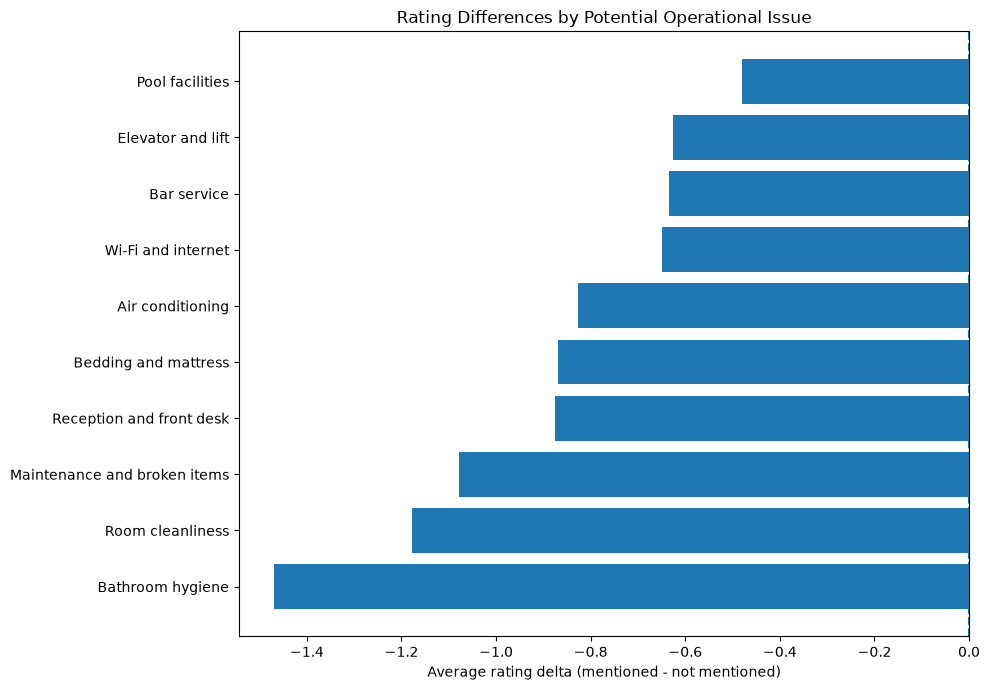

In [27]:
# Visualise rating differences

plot_data = issue_summary.sort_values("Average rating delta")

plt.figure(figsize=(10, 7))

plt.barh(
    plot_data["Issue"],
    plot_data["Average rating delta"]
)

plt.axvline(0, linestyle="--")
plt.xlabel("Average rating delta (mentioned - not mentioned)")
plt.title("Rating Differences by Potential Operational Issue")
plt.tight_layout()
plt.show()

In [28]:
# Inspect actual reviewed for the identified top issues

top_issues = (
    issue_summary
    .head(3)["Issue"]
    .tolist()
)

for issue in top_issues:
    print(f"\n--- {issue} ---")

    sample = df_clean.loc[
        df_clean[issue],
        [
            "review_score",
            "room_nights",
            "guest_country",
            "review_negative"
        ]
    ].dropna(subset=["review_negative"])

    pd.set_option("display.max_colwidth", None)
    pd.set_option("display.max_rows", 100)

    display(
        sample.sample(
            min(10, len(sample)),
            random_state=42
        )
    )


--- Bathroom hygiene ---


,review_score,room_nights,guest_country,review_negative
1159355,7.0,1,Mejok,"Unfortunately, the room looked a little tired and could do with a coat of paint. The shower had limescale, mould, and needed regrouting."
1490002,5.0,3,Zuc,"Our room was small and with small I mean, very small. There was no room left to actually walk. There was a bed and that was basically it. With our two big suitcases, one small and a backpack it was very tight. The room wasn&#39;t that clean, it looked like the curtains had mould."
673025,9.0,3,Mejok,"We had a weird smell in our room. The whole floor had it when we arrived but we put it down to all the cleaning. When we returned to our room, it was still there. Kind of like mouldy water in the pipes. The staff were great and moved us to a new floor. I didn&#39;t like all the products in the room. Next to the coffee set and in the fridge. Would prefer they suppied what was free and had options available."
1326628,8.0,2,Nukeye,Bathroom shower was dirty. No one could provide me with the access code for the tv. There was no orange juice at breakfast. The elevator sounded as if it would get stuck each time i went on it. No one came to tidy the room when we left.
889970,8.0,1,Zuc,Our room had a bit of a smell. Mould perhaps? Not enough to request a room change but it was definitely there. Not much space for 2-3 suitcases in the standard twin.
1319238,6.0,3,Nukeye,mold in bathroom. They wanted 19.00 for Toast. we never ate at hotel. Staff was not Kind or helpful until check out.
403772,8.0,1,Mejok,Bit of mould round the bath&#47;shower needs attention.
957113,9.0,1,Nukeye,Food and bar a little pricey. The bathroom sink had mold under edge of sink. Would have liked the airport shuttle to be available in mid-day when we arrived.
128796,10.0,4,Nukeye,the bathroom was very small and had wood features in the shower which seemed to be attracting mold
1095638,7.0,1,Nukeye,Our room had a strong smell. Kind of musty and moldy. Never have had this happen but it kicked up my asthma and was very uncomfortable. 2 days later I’m still trying to get my breathing and asthma under control. Also most of staff we encountered (not all!) had a quick and grumpy edge to them.



--- Room cleanliness ---


,review_score,room_nights,guest_country,review_negative
315615,6.0,1,Mejok,"Only the grill was open for food which was dry and chips undercooked. Room seemed tired &amp; dated - no plug socket by the bed. Bedside tables were really dusty, I had to give them a wipe down. Bed wasn’t the most comfortable. I was cold at one point with no means to put heating on as temperature dropped. No room service. Could not phone reception - or at least no information on how to call them. Overall I was a rather disappointed."
823873,8.0,1,Bemab,"This time our room was not very clean, surface was dusty and sheets were not clean. We asked to change sheets and they did, so everything was fine at the end. Staff was very polite all the time, but during breakfast they forgot our order. We were waiting for almost one hour, when we finally asked when the food is going to arrive, waiter said he forgot to order. We understand mistakes happen, especially when it is busy, but dirty sheets first, then forgotten breakfast...there is a buffet there as well, so if you see it&#39;s busy, I guess it is better to grab food from there rather than order from the menu"
1444091,5.0,1,Wiz,Dirty room
1516606,7.0,4,Mejok,The hotel was quite shabby. Our room was dusty and some of the furniture was very worn. The bathroom was in poor condition.
893440,7.0,2,Mejok,- Room was compact - Underneath the bed was dusty and didn’t seem like it had been cleaned -
1051950,8.0,4,Nukeye,The room was very small (which we anticipated; but it was smaller than we&#39;d thought). The carpet seemed a bit dusty. The hallway smelled musty.
249312,10.0,2,Nukeye,"The sheets and floor seemed clean, but the walls and floorboards and other fixtures were dirty and dusty."
1477362,10.0,1,Mejok,nothing to not like really! I did feel the rooms could have been a little bit cleaner as it seemed a bit dusty and there was a mark on the bedding but they are only little things. I was very happy with my stay
1415207,9.0,5,Fanir,Just one little reservation - the bad smell coming from shower drain in the bathroom
920194,9.0,1,Mejok,Some dusty parts in the room



--- Air conditioning ---


,review_score,room_nights,guest_country,review_negative
837858,9.0,1,Mejok,Aircon&#47; heating too noisy to use. Windows old and not sound proofed. Tricky to find entrance.
103192,8.0,2,Nukeye,No air conditioning. The day we stayed it was warm.
918329,8.0,2,Vema,"On first night there was low water pressure in shower, but it was quickly fixed by our request! The air conditioning requires upgrade especially regarding the current warming - it was absolutely not sufficient"
592034,8.0,4,Buzi,Irritating elevator and aircondition control
501600,10.0,3,Mejok,"The rooms didn’t seem very soundproof, as I could hear other guests talking, coughing &amp; sneezing, &amp; walking around in their rooms. It wasn’t clear how the air conditioning in the room worked as the room temperature didn’t seem to change when I changed the temperature on the control panel"
1238919,7.0,2,Gobuf,Aircon isn&#39;t great Prices are very expensive compared to rest of Zagreb Bathroom doesn&#39;t allow for any privacy
565937,7.0,10,Tuleho,the room is very small. If you have big luggage you can’t open in the room. And remember when you book you must ask the room have windows…This is the first time I book the room without windows 😩😩😩.Because every time when I went to UK I book the room in the another hotel always have windows… But this hotel they have room without windows. I with my daughter can’t breath when We slept. Lucky they had air conditioning 🤣🤣🤣..forgot to take a picture 🤣🤣
1390264,9.0,14,Mejok,It was very hot in August and we had problems with the aircon. We are old and found clambering into a slippery bath with no mat to shower was tricky- as was the uneven temperature control on the latter( hot on moment then cool).
1265402,7.0,5,Zuc,Very very noisy room at front of hotel. Only way to sleep is to run aircon full blast to drown out the street noise from the nightly street party below. I got sick from this. (Alternatively you could stay out until 2am and sleep during the day when it’s super quiet). No room service. No bar. Restaurant never open. Pity because pool deck is lovely to watch the sunset so it would have been nice to be able to get a drink up there. Only 4 small bottles of water provided for 5 night stay. No clean towels provided after room cleaned. No iron. Breakfast is very basic and pretty boring…particularly after the same thing 5 days in a row. Also doesn’t start until 7.30am so if you’re being picked up for a day tour you’ll miss out. I must say I was there over the Easter weekend so maybe this affected the services.
1567303,7.0,1,Made,aircon was on and off.


## Clustering

In [29]:
import pandas as pd
import re
import matplotlib.pyplot as plt

# Select non-empty negative reviews
cluster_data = df_clean["review_negative"].dropna().astype(str)
cluster_data = cluster_data[cluster_data.str.strip().ne("")]

# Sample reviews for faster processing
cluster_data = cluster_data.sample(
    n=min(30000, len(cluster_data)),
    random_state=42
).reset_index(drop=True)

print("Reviews selected for clustering:", len(cluster_data))

Reviews selected for clustering: 30000


In [30]:
# Convert reviews into TF-IDF features

from sklearn.feature_extraction.text import TfidfVectorizer

custom_stop_words = [
    "hotel", "room", "rooms", "staff", "good", "great",
    "nice", "like", "little", "bit", "just", "also",
    "really", "one", "get", "got", "well", "back",
    "would", "could", "didn", "didnt", "wasn", "wasnt",
    "isn", "isnt", "night", "day"
]

tfidf = TfidfVectorizer(
    stop_words=custom_stop_words,
    ngram_range=(1, 2),
    min_df=5,
    max_df=0.90,
    max_features=10000,
    sublinear_tf=True
)

X = tfidf.fit_transform(cluster_data)

print("TF-IDF matrix shape:", X.shape)

TF-IDF matrix shape: (30000, 10000)


In [31]:
# K-means clustering
from sklearn.cluster import KMeans

k = 8

kmeans = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans.fit_predict(X)

cluster_results = pd.DataFrame({
    "review_negative": cluster_data,
    "cluster": cluster_labels
})

print("Clustering completed.")
print(cluster_results["cluster"].value_counts().sort_index())

Clustering completed.
cluster
0     2396
1     1192
2     2085
3      615
4      466
5      611
6    10091
7    12544
Name: count, dtype: int64


In [32]:
# Understand what each cluster represents
terms = tfidf.get_feature_names_out()

for cluster_id in range(k):
    center = kmeans.cluster_centers_[cluster_id]
    top_indices = center.argsort()[-10:][::-1]
    top_terms = terms[top_indices]

    print(f"\nCluster {cluster_id}")
    print("Top terms:", ", ".join(top_terms))

    examples = cluster_results.loc[
        cluster_results["cluster"] == cluster_id,
        "review_negative"
    ]

    display(
        examples.sample(
            n=min(5, len(examples)),
            random_state=42
        ).to_frame()
    )


Cluster 0
Top terms: nothing, more, no, zone, go there, goes, god, go with, go up, go to


,review_negative
5468,Nothing.
2362,Nothing.
18881,Nothing.
24367,Nothing
20923,Nothing



Cluster 1
Top terms: small, very small, very, was small, was, the, small and, and, too small, small but


,review_negative
23217,"small rooms, not very clean, equipment was ,, kind of overused,, needed replacement many things"
6791,The double room was very average and didn’t have some of the most basic amenities such as drawers&#47;shelves for your clothes. The bathroom was small and the shower had poor drainage.
7251,Some more hangers can be provided. The wash basin is a bit small and the water is easily splashed around.
4311,"Maybe this hotel is newly build and modern, the price is a bit pricy. Basement private car parking lots is quite small, space limited."
14913,Shower was very small



Cluster 2
Top terms: breakfast, breakfast was, the breakfast, the, was, and, for, not, at, no


,review_negative
19793,Lack of breakfast…
11775,"Breakfast was not up to standard, need to be evaluated by hotel"
29439,"There were no delicious sweet pies, pancakes, croissants for breakfast, coffee."
19669,Very noisy (large streets with heavy traffic nearby). Breakfast is served too late for someone on a business trip (7h30).
23729,Breakfast could have a few more options that aren&#39;t sweets&#47;cakes or Indonesian&#47;Asian food. Alternative milk options would be great.


... (6 outputs left out)


Cluster 6
Top terms: no, nothing, to, was, not, the, and, parking, for, nothing to


,review_negative
18729,"old fashioned facilities, rooms without refrigerator."
1804,Shower with curtain. I expected the glass.
24707,"Cold showers, if there was any hot water it was a dribble. Outdoor Spa’s available- no pool, no towels for Spa"
28859,nothing that comes to mind
29671,Nothing it was lovely



Cluster 7
Top terms: the, to, in, was, and, it, in the, of, we, not


,review_negative
7434,"There was a fan but it was hot during the day. I was there at the beginning of April and the nights were cool so, with the windows opened, it cooled down but it took a while. Also, if you did want to cook there was only crockery, not cutlery or cooking utensils and, although there was dishwashing liquid, there was no teatowel."
4355,"Unfortunately, the place is very consumed and needs renovation. The bed is 6&#47;10 in comfort."
3110,"No lift, super hot in the public areas, non working kettle so could not make a hot beverage. Staff heartfully meant to check it but did not happen after the second reminder."
27099,"Room was rather small and basic. Internet connection (not even speaking about wifi, but about connection as such) was very poor, I had some work to finish and had to so in the lobby which is not very inviting. Don&#39;t expect any extras beyond bed sheets, towels and shower gel. I am not sure if at the time there was any in event in Brussels causing the prices to skyrocket, but as one of the last available hotels in the centre with 175€ per night I considered this rather overpriced. No breakfast offer."
28727,"It&#39;s a bit far from the Sanctuary so you do not get the same feeling of Fatima as if you stay close to the center. But we wanted to walk the trail to Nazare so for us it was fine. The restaurant was very good but we would have appreciated a choice of 37,5 cl wine bottles."


Based on the above clusters, only cluster 1 & 2 seem helpful. Filter out non-useful reviews and run TF-IDF and K-means.

In [ ]:
# Remove empty and non-informative negative reviews
text = (
    df_clean["review_negative"]
    .fillna("")
    .astype(str)
    .str.strip()
    .str.lower()
)

non_informative = (
    text.eq("")
    | text.isin([
        "nothing", "nothing.", "n/a", "na",
        "no complaints", "no complaints."
    ])
)

df_cluster = df_clean.loc[~non_informative].copy()

print("Original hotel reviews:", len(df_clean))
print("Reviews retained:", len(df_cluster))
print("Reviews removed:", int(non_informative.sum()))

Original hotel reviews: 922116
Reviews retained: 628337
Reviews removed: 293779


In [34]:
# Rerun TF-IDF and K-means
import re
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans

# Remove empty and very short reviews
cluster_data = (
    df_cluster["review_negative"]
    .dropna()
    .astype(str)
    .str.strip()
)

cluster_data = cluster_data[cluster_data.str.len() >= 15]

# Remove common non-informative responses
cluster_data = cluster_data[
    ~cluster_data.str.lower().str.fullmatch(
        r"nothing\.?|n/?a|no complaints\.?|none\.?|nil\.?",
        na=False
    )
]

# Sample for faster experimentation
cluster_data = cluster_data.sample(
    min(30000, len(cluster_data)),
    random_state=42
).reset_index(drop=True)

# Remove HTML entities and normalise whitespace
def clean_review(text):
    text = text.lower()
    text = re.sub(r"&#\d+;|&amp;|&quot;|&apos;", " ", text)
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"[^a-z\s']", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

cluster_data = cluster_data.apply(clean_review)

custom_stop_words = [
    "hotel", "hotels", "room", "rooms", "stay", "stayed",
    "place", "really", "quite", "just", "like", "good",
    "great", "nice", "well", "also", "one", "would",
    "could", "get", "got", "thing", "things", "bit",
    "little", "much", "back", "there", "very", "was",
    "were", "didn", "doesn", "isn", "wasn", "didnt",
    "noth", "everything"
]

tfidf = TfidfVectorizer(
    stop_words=custom_stop_words,
    ngram_range=(1, 2),
    min_df=10,
    max_df=0.80,
    max_features=15000,
    sublinear_tf=True
)

X = tfidf.fit_transform(cluster_data)

print("Reviews:", len(cluster_data))
print("TF-IDF features:", X.shape[1])

Reviews: 30000
TF-IDF features: 11160


In [ ]:
# Compare different cluster counts
from sklearn.metrics import silhouette_score

results = []
sample_size = min(5000, X.shape[0])

for k in [5, 6, 8, 10]:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X)

    score = silhouette_score(
        X,
        labels,
        sample_size=sample_size,
        random_state=42
    )

    results.append({
        "Clusters": k,
        "Silhouette score": score,
        "Smallest cluster": pd.Series(labels).value_counts().min(),
        "Largest cluster": pd.Series(labels).value_counts().max()
    })

cluster_comparison = pd.DataFrame(results)
display(cluster_comparison.round(3))

,Clusters,Silhouette score,Smallest cluster,Largest cluster
0,5,0.007,408,13479
1,6,0.007,355,11869
2,8,0.008,354,11043
3,10,0.009,182,9385


## HDBSCAN
Since the above code show that K-means does not improve the silhoutte score, we will try HDBSCAN as this can leave reviews unassigned when they do not belong to a clear cluster.

In [36]:
%pip install hdbscan

  Using cached hdbscan-0.8.44-cp312-cp312-macosx_10_13_universal2.whl.metadata (15 kB)
Using cached hdbscan-0.8.44-cp312-cp312-macosx_10_13_universal2.whl (2.6 MB)
Note: you may need to restart the kernel to use updated packages.


In [37]:
# Run HDBSCAN on existing TF-IDF matrix
import hdbscan
import pandas as pd

clusterer = hdbscan.HDBSCAN(
    min_cluster_size=100,
    min_samples=10,
    metric="euclidean",
    cluster_selection_method="eom"
)

hdbscan_labels = clusterer.fit_predict(X)

hdbscan_results = pd.DataFrame({
    "review_negative": cluster_data,
    "cluster": hdbscan_labels
})

# -1 means HDBSCAN classified the review as noise
print("Cluster sizes:")
print(
    hdbscan_results["cluster"]
    .value_counts()
    .sort_index()
)

noise_pct = (hdbscan_labels == -1).mean() * 100
print(f"\nReviews classified as noise: {noise_pct:.2f}%")

Cluster sizes:
cluster
-1    26899
 0     1500
 1      172
 2     1290
 3      139
Name: count, dtype: int64

Reviews classified as noise: 89.66%


## BERTopic

To select the best model, K-means, HDBSCAN and BERTopic was assessed. K-means produced weak separation according to the sampled silhouette comparisons, while HDBSCAN classified a large proportion of reviews as noise under the tested settings.

We will then use BERTopic as the main topic-discovery method as it combines document embeddings, dimensionality reduction and density-based clustering. The model is fitted once on a clearly defined sample so that document text, row metadata and topic assignments remain aligned.

Note: Topic IDs are model-generated and can change if the sample or parameters change. Topic labels must be checked against the current topic representations and actual review examples.


In [38]:
# Prepare one consistent modelling sample for BERTopic and anomaly detection
# Retain the original row index so model outputs can be linked back to df_clean.

import numpy as np
import pandas as pd

model_df = df_cluster.loc[
    df_cluster["review_negative"].notna()
    & df_cluster["review_negative"].astype(str).str.strip().ne(""),
    [
        "review_negative", "review_score", "room_nights",
        "guest_country", "accommodation_country",
        "accommodation_star_rating", "guest_type"
    ]
].copy()

model_df["review_negative"] = model_df["review_negative"].astype(str).str.strip()
model_df = model_df[model_df["review_negative"].str.len() >= 15].copy()

# Remove common non-informative responses
non_informative_pattern = (
    r"(?i)^(nothing\.?|n/?a|no complaints?\.?|none\.?|nil\.?)$"
)
model_df = model_df[
    ~model_df["review_negative"].str.fullmatch(non_informative_pattern, na=False)
].copy()

model_df = model_df.sample(
    n=min(30000, len(model_df)),
    random_state=42
).reset_index(names="original_row_index")

cluster_data = model_df["review_negative"].tolist()

print("Reviews prepared for modelling:", len(model_df))
print("Unique original row references:", model_df["original_row_index"].nunique())
display(model_df.head())


Reviews prepared for modelling: 30000
Unique original row references: 30000


,original_row_index,review_negative,review_score,room_nights,guest_country,accommodation_country,accommodation_star_rating,guest_type
0,589049,I wouldn’t complain at all,10.0,3,Panasi,Italy,4.0,Family with children
1,1315204,"The bed was so uncomfortable!!!I haven’t seen a spring mattress in so long. As long as the night was I couldn’t find a good spot on that bed. The carpet was torn and needed to be replace. Also, the ceiling in the bathroom has seen better days.",6.0,2,Nukeye,United States of America,3.0,Family with children
2,1551347,no sound proofing,6.0,2,Tig,Philippines,3.0,Solo traveller
3,571316,Slight issue with the plumbing. Sink was blocked a little bit meaning that it took some time to clear Toilet Bidet didnt work - Not an issue if you dont use it,7.0,12,Mejok,Japan,4.0,Solo traveller
4,272236,"There were rusts on some furnitures, batthub could use better maintaining, there were black moulds on the lining of the batthub glass. The airconditioning was also very loud.",7.0,1,Zuc,Australia,4.0,Group


In [40]:
%pip install bertopic

  Using cached bertopic-0.17.4-py3-none-any.whl.metadata (24 kB)
  Using cached umap_learn-0.5.12-py3-none-any.whl.metadata (24 kB)
  Using cached plotly-7.1.0-py3-none-any.whl.metadata (8.8 kB)
  Using cached sentence_transformers-6.2.0-py3-none-any.whl.metadata (20 kB)
  Using cached llvmlite-0.50.0-cp312-cp312-macosx_12_0_arm64.whl.metadata (5.1 kB)
  Using cached pyyaml-6.0.3-cp312-cp312-macosx_11_0_arm64.whl.metadata (2.4 kB)
  Using cached h11-0.16.0-py3-none-any.whl.metadata (8.3 kB)
  Using cached sympy-1.14.0-py3-none-any.whl.metadata (12 kB)
  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
  Using cached mpmath-1.3.0-py3-none-any.whl.metadata (8.6 kB)
  Using cached numba-0.68.1-cp312-cp312-macosx_12_0_arm64.whl.metadata (2.8 kB)
  Using cached pynndescent-0.7.0-py3-none-any.whl.metadata (6.9 kB)
  Using cached shellingham-1.5.4-py2.py3-none-any.whl.metadata (3.5 kB)
  Using cached mdurl-0.1.2-py3-none-any.whl.metadata (1.6 kB)
Using cached bertopic-0.17.4-py3-n

In [ ]:
# Fit BERTopic once on the modelling sample

from bertopic import BERTopic

topic_model = BERTopic(
    language="english",
    min_topic_size=100,
    nr_topics="auto",
    verbose=True
)

topics, probabilities = topic_model.fit_transform(cluster_data)

model_df["topic"] = topics

assert len(model_df) == len(topics), "Topic assignments are not aligned with modelling rows."

topic_info = topic_model.get_topic_info()
display(topic_info[["Topic", "Count", "Name", "Representation"]])

print("\nTopic counts including outliers:")
display(model_df["topic"].value_counts().sort_index().to_frame("review_count"))


/Users/kayeannesabater/Audit Analytics Assignment 2/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1103 23:47:28.042000 71525 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
2026-11-03 23:47:32,345 - BERTopic - Embedding - Transforming documents to embeddings.
Batches: 100%|██████████| 938/938 [00:21<00:00, 43.29it/s]
2026-11-03 23:47:56,165 - BERTopic - Embedding - Completed ✓
2026-11-03 23:47:56,166 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-11-03 23:48:31,224 - BERTopic - Dimensionality - Completed ✓
2026-11-03 23:48:31,228 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-11-03 23:48:35,069 - BERTopic - Cluster - Completed ✓
2026-11-03 23:48:35,071 - BERTopic - Representa

,Topic,Count,Name,Representation
0,-1,7509,-1_the_and_to_was,"[the, and, to, was, in, room, of, it, not, for]"
1,0,3554,0_breakfast_was_the_food,"[breakfast, was, the, food, and, for, to, of, restaurant, not]"
2,1,2117,1_coffee_room_the_in,"[coffee, room, the, in, air, was, no, it, and, to]"
3,2,1971,2_noise_noisy_the_hear,"[noise, noisy, the, hear, night, from, room, and, loud, was]"
4,3,1964,3_nothing_everything_perfect_all,"[nothing, everything, perfect, all, was, great, good, complaints, complain, anything]"
5,4,1239,4_room_small_rooms_the,"[room, small, rooms, the, but, bit, carpet, and, was, is]"
6,5,1170,5_staff_check_to_and,"[staff, check, to, and, the, reception, in, was, we, at]"
7,6,1035,6_parking_car_park_to,"[parking, car, park, to, the, is, hotel, for, was, and]"
8,7,992,7_to_location_from_the,"[to, location, from, the, taxi, is, hotel, airport, walk, far]"
9,8,991,8_pool_the_was_and,"[pool, the, was, and, swimming, spa, to, it, is, in]"



Topic counts including outliers:


,review_count
topic,
-1,7509
0,3554
1,2117
2,1971
3,1964
4,1239
5,1170
6,1035
7,992


## Inspect and label discovered topics

We cannot assign a topic label from the topic ID alone. Inspect both the top terms and representative reviews. The label dictionary below is deliberately generated from the current model output where possible, so we need to manually review and refine it after running the cells.


In [42]:
# Inspect top terms and representative reviews for every topic
topic_examples = {}

for topic_id in sorted(model_df["topic"].unique()):
    print(f"\n{'=' * 70}\nTopic {topic_id}")
    print("Top terms:", topic_model.get_topic(topic_id))

    examples = model_df.loc[
        model_df["topic"] == topic_id, "review_negative"
    ]

    display(
        examples.sample(min(5, len(examples)), random_state=42)
        .to_frame(name="representative_review")
    )



Topic -1
Top terms: [('the', np.float64(0.030404112899677187)), ('and', np.float64(0.024502196945018016)), ('to', np.float64(0.02284623155938524)), ('was', np.float64(0.022072196288611276)), ('in', np.float64(0.021843030651652804)), ('room', np.float64(0.020483243215635508)), ('of', np.float64(0.018504606579935273)), ('it', np.float64(0.017816209238964684)), ('not', np.float64(0.01767569614657827)), ('for', np.float64(0.017506492004186396))]


,representative_review
17926,"The water supply for drinking was not enough, though we managed to get help from the amazing housekeepers who were quick to respond. The soap for bathing wasn&#39;t enough."
22511,The pipes make this very intense noise and would let you rest during the night The restroom floor is slippery at the entrance
18800,A budget 4 star hotel that is missing some of the bells and whistles of a full 4 star hotel (the bathroom was slightly dated). The room was also quite small.
4302,Wasn&#39;t very comfortable &amp; the sheet&#47;blanket didn&#39;t cover shoulders completely. The AC wouldn&#39;t run until we were hot then go on &amp; get cold so I had to take off sheet&#47;blanket until it ran then cover up-so interrupted sleep. As stated in pros-pool issue w&#47;shocking 24 hr later could hardly breathe next night not as bad but didn&#39;t want to use. No dressers left room feeling open &amp; modern. Except it had only 5 hangers which were used up w&#47;coats. So we lived out of backpacks we took &amp; was awkward when staying 3 nights.
19341,"The staffing levels were poor in the bar and restaurant, the bedside tables were not dusted and the pull out bed mattress was uncomfortable. We waited over 45mins for food when we had booked a table."



Topic 0
Top terms: [('breakfast', np.float64(0.06041355964120944)), ('was', np.float64(0.026760743493315142)), ('the', np.float64(0.026753842115717553)), ('food', np.float64(0.025843421600988608)), ('and', np.float64(0.024644052460055493)), ('for', np.float64(0.022572702191617545)), ('to', np.float64(0.02019026599269903)), ('of', np.float64(0.019862695337165077)), ('restaurant', np.float64(0.01930363986547019)), ('not', np.float64(0.01860859827766073))]


,representative_review
2683,"Breakfast is not varied, needs improvement"
19118,"The breakfast was just an OK at best continental variety. The toaster didn&#39;t work well and the bagels were stale and tasteless. The fruit was limited with bananas, and apples perhaps."
20229,The breakfast plates were cold which meant the good food went cold too quickley.
29215,"For the evening meal the menu was air Italian.so I found the choice was limited for some people. Meals quite expensive, extras had to be paid for."
22091,The pricing of the dinner. 2000 for basic French fries and kleinur for 2000. Crazy expensive when you compare it to other places and room price at this hotel



Topic 1
Top terms: [('coffee', np.float64(0.03819403732435524)), ('room', np.float64(0.0358255960178527)), ('the', np.float64(0.030443822110158357)), ('in', np.float64(0.02955121934934253)), ('air', np.float64(0.028928952625319592)), ('was', np.float64(0.027114315435292906)), ('no', np.float64(0.02651075450012325)), ('it', np.float64(0.02268001577570861)), ('and', np.float64(0.021707615100095896)), ('to', np.float64(0.021693052814328265))]


,representative_review
5739,Beds could be better and my room didn&#39;t have air conditioning.
15118,The coffee shop sells itself as a Starbucks but it’s really just an automatic coffee machine. This is fine but the price didn’t really match what it was.
3571,- No air conditioning. - No phone in case you want to call the room services.
4937,My room (no.6) has a gap around the front door and was very draftee. Couldn’t find the heater remote to warm the room up. Just rugged up in bed.
5405,"Air conditioner stopped working, but i asked for help and staff came immediately to solve."


... (44 outputs left out)


Topic 24
Top terms: [('ants', np.float64(0.07621264126724575)), ('mosquitoes', np.float64(0.04170840175851679)), ('in', np.float64(0.0408189827642391)), ('room', np.float64(0.038106677274386526)), ('cockroach', np.float64(0.03615828920867585)), ('mosquitos', np.float64(0.035877755002894494)), ('the', np.float64(0.03252146308008844)), ('our', np.float64(0.032471893709876055)), ('there', np.float64(0.03141540632863198)), ('cockroaches', np.float64(0.031115299128613126))]


,representative_review
14159,Saw Cockroaches
2784,Found a couple of small cockroaches during my stay. toilet was aged and mattresses were stiff and hard.
26366,Wort is WIFI Mosquito are too much in room Found some Cockroach in room
12191,"I really don’t have nothing bad to say but , when I stepped out my room In the morning there was a huge inch and half roach on top of the wall .."
21706,in the room there are ants at the coffee area... maybe due to the furniture wood look old already



Topic 25
Top terms: [('suitcases', np.float64(0.06812886647303609)), ('luggage', np.float64(0.05861583541568105)), ('small', np.float64(0.05654286365223856)), ('room', np.float64(0.05184738537210491)), ('space', np.float64(0.047120770497640144)), ('for', np.float64(0.038474501750822926)), ('suitcase', np.float64(0.03516052617407725)), ('to', np.float64(0.030985619832661366)), ('the', np.float64(0.03054493730917529)), ('was', np.float64(0.028045136936285832))]


,representative_review
10453,"Small details like no towel hangers in the bathroom. The room was big enough for me alone for two days, but could have been a problem if there were two people with big suitcases"
19014,We had a twin and triple room. They were both pretty small with limited room to put suitcases. This was especially so in the triple room. The rooms only has 1 usb charging point and no universal switches.
18990,"Room was very small, no room for luggage for 2 people."
15763,Our room was on the inside of the courtyard so we had to lug our belongings the whole way. Luckily we packed overnight bags
13624,limited space for luggage


In [58]:
# Create a first draft topic label dictionary
# Unclear topics are intentionally kept broad rather than over-interpreted

topic_labels = {
    -1: "Unassigned / outlier reviews"
}

for topic_id in sorted(model_df["topic"].unique()):
    if topic_id != -1:
        topic_labels[topic_id] = f"Topic {topic_id} - requires review"

# Edit topic labels here
topic_labels.update({
0: "Breakfast and food",
1: "Coffee and room-related experiences",
2: "Noise",
3: "Positive or no-complaint expressions",
4: "Room size and condition",
5: "Staff and check-in",
6: "Parking",
7: "Location and accessibility",
8: "Pool and spa facilities",
9: "Positive or no-complaint expressions",
10: "Shower and water facilities",
11: "Elevators",
12: "Beds and mattresses",
13: "Bathroom and toilet facilities",
14: "Odor",
15: "Wifi and internet",
16: "Television and channels",
17: "Pillows",
18: "Room lighting",
19: "Towels and linen",
20: "Price and value",
21: "Views, balconies and windows",
22: "Positive or no-complaint expressions",
23: "Electrical sockets and charging",
24: "Insects and pests",
25: "Room size and luggage space"
})

model_df["topic_label"] = model_df["topic"].map(topic_labels)

print("Topics without labels:", model_df.loc[model_df["topic_label"].isna(), "topic"].unique())
display(
    model_df.groupby(["topic", "topic_label"], dropna=False)
    .size().reset_index(name="review_count")
    .sort_values("review_count", ascending=False)
)


Topics without labels: []


,topic,topic_label,review_count
0,-1,Unassigned / outlier reviews,7509
1,0,Breakfast and food,3554
2,1,Coffee and room-related experiences,2117
3,2,Noise,1971
4,3,Positive or no-complaint expressions,1964
5,4,Room size and condition,1239
6,5,Staff and check-in,1170
7,6,Parking,1035
8,7,Location and accessibility,992
9,8,Pool and spa facilities,991


In [61]:
# Topic-level profile: volume, rating and low-rating prevalence
# Low rating is defined as review_score <= 5 for consistency with earlier sections.

overall_avg_rating = model_df["review_score"].mean()
overall_low_rate = model_df["review_score"].dropna().le(5).mean() * 100

topic_summary = (
    model_df.groupby(["topic", "topic_label"], dropna=False)
    .agg(
        review_count=("review_score", "count"),
        average_rating=("review_score", "mean"),
        median_rating=("review_score", "median"),
        average_nights=("room_nights", "mean"),
        low_rating_pct=("review_score", lambda x: x.dropna().le(5).mean() * 100)
    )
    .reset_index()
)

topic_summary["low_rating_delta_pp"] = (
    topic_summary["low_rating_pct"] - overall_low_rate
)
topic_summary["average_rating_delta"] = (
    topic_summary["average_rating"] - overall_avg_rating
)
topic_summary["share_of_model_sample_pct"] = (
    topic_summary["review_count"] / len(model_df) * 100
)

topic_summary = topic_summary.sort_values(
    ["low_rating_delta_pp", "review_count"], ascending=[False, False]
)

print(f"Overall average rating: {overall_avg_rating:.2f}")
print(f"Overall low-rating rate (<=5): {overall_low_rate:.2f}%")
display(topic_summary.round(2))


Overall average rating: 8.42
Overall low-rating rate (<=5): 1.31%


,topic,topic_label,review_count,average_rating,median_rating,average_nights,low_rating_pct,low_rating_delta_pp,average_rating_delta,share_of_model_sample_pct
25,24,Insects and pests,126,7.75,8.0,2.80,6.35,5.04,-0.68,0.42
15,14,Odor,553,7.88,8.0,2.73,3.44,2.13,-0.55,1.84
6,5,Staff and check-in,1170,8.20,8.0,2.42,2.39,1.09,-0.22,3.90
0,-1,Unassigned / outlier reviews,7509,8.19,8.0,2.74,2.02,0.72,-0.23,25.03
20,19,Towels and linen,268,8.26,8.0,2.97,1.87,0.56,-0.17,0.89
5,4,Room size and condition,1239,8.12,8.0,2.55,1.69,0.39,-0.31,4.13
12,11,Elevators,866,8.45,8.0,2.72,1.62,0.31,0.03,2.89
16,15,Wifi and internet,519,8.33,8.0,2.88,1.54,0.23,-0.09,1.73
17,16,Television and channels,333,8.44,8.0,2.37,1.50,0.19,0.01,1.11
14,13,Bathroom and toilet facilities,572,8.33,8.0,2.65,1.40,0.09,-0.10,1.91


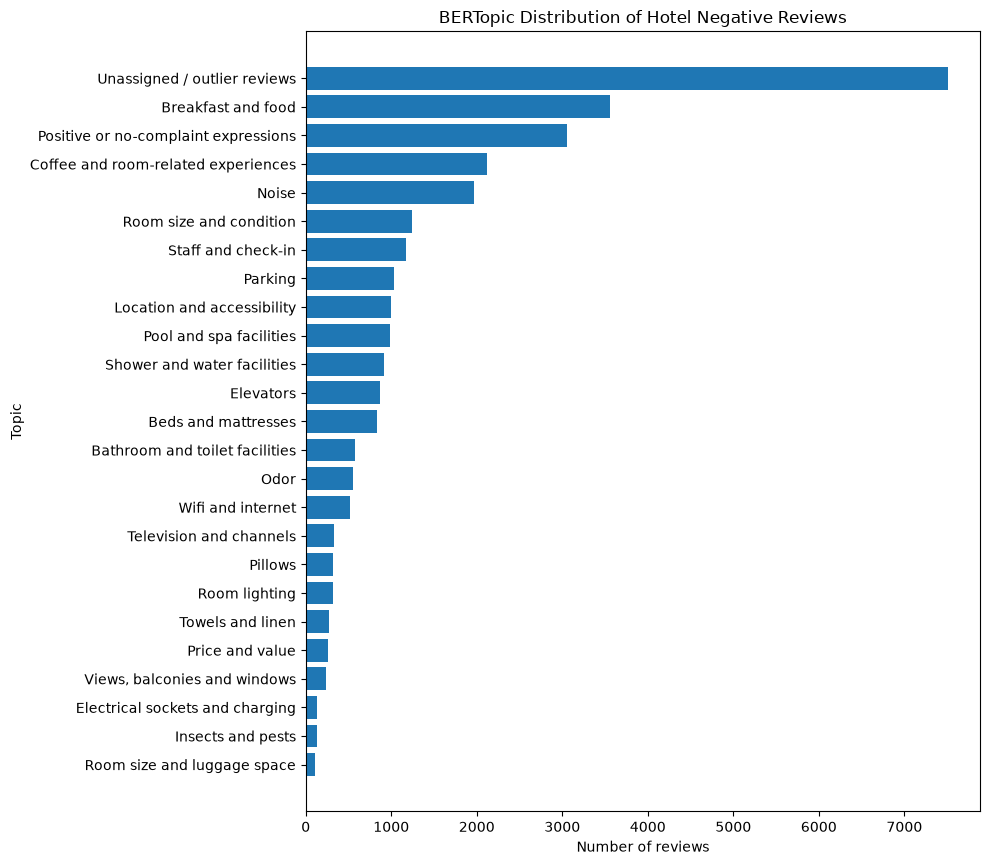

In [62]:
# Visualise BERTopic topic sizes (show outliers separately)
topic_plot = (
    model_df["topic_label"].value_counts()
    .rename_axis("topic_label")
    .reset_index(name="review_count")
    .sort_values("review_count", ascending=True)
)

plt.figure(figsize=(10, max(5, len(topic_plot) * 0.35)))
plt.barh(topic_plot["topic_label"], topic_plot["review_count"])
plt.xlabel("Number of reviews")
plt.ylabel("Topic")
plt.title("BERTopic Distribution of Hotel Negative Reviews")
plt.tight_layout()
plt.show()


### Preliminary topic prioritisation

A high topic count indicates frequency, not necessarily severity. We will compare each topic's low-rating rate with the overall modelling-sample rate. Small topics should be flagged for manual review because their rates can be unstable.

The table below uses a minimum count threshold (we can adjust) for the visual prioritisation. 


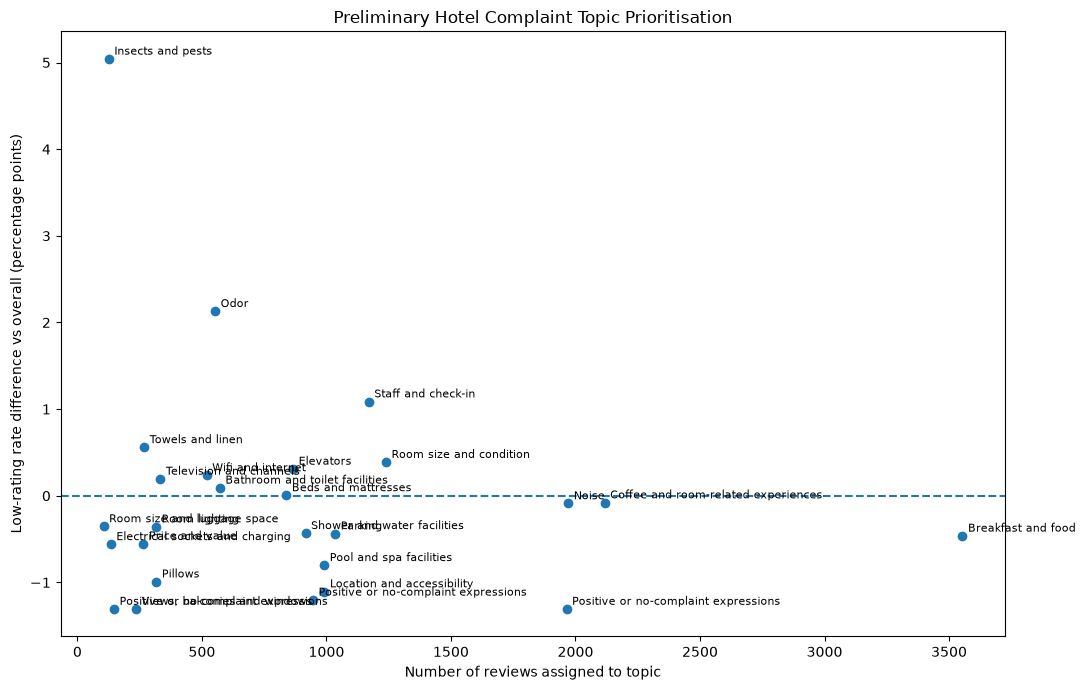

,topic,topic_label,review_count,low_rating_pct,low_rating_delta_pp,average_rating_delta
25,24,Insects and pests,126,6.35,5.04,-0.68
15,14,Odor,553,3.44,2.13,-0.55
6,5,Staff and check-in,1170,2.39,1.09,-0.22
20,19,Towels and linen,268,1.87,0.56,-0.17
5,4,Room size and condition,1239,1.69,0.39,-0.31
12,11,Elevators,866,1.62,0.31,0.03
16,15,Wifi and internet,519,1.54,0.23,-0.09
17,16,Television and channels,333,1.50,0.19,0.01
14,13,Bathroom and toilet facilities,572,1.40,0.09,-0.10
13,12,Beds and mattresses,839,1.31,0.00,-0.15


In [63]:
# Prioritisation matrix: topic volume versus excess low-rating rate
MIN_TOPIC_COUNT = 100

priority_df = topic_summary[
    (topic_summary["topic"] != -1)
    & (topic_summary["review_count"] >= MIN_TOPIC_COUNT)
].copy()

plt.figure(figsize=(11, 7))
plt.scatter(
    priority_df["review_count"],
    priority_df["low_rating_delta_pp"]
)

for _, row in priority_df.iterrows():
    plt.annotate(
        str(row["topic_label"]),
        (row["review_count"], row["low_rating_delta_pp"]),
        fontsize=8,
        xytext=(4, 3),
        textcoords="offset points"
    )

plt.axhline(0, linestyle="--")
plt.xlabel("Number of reviews assigned to topic")
plt.ylabel("Low-rating rate difference vs overall (percentage points)")
plt.title("Preliminary Hotel Complaint Topic Prioritisation")
plt.tight_layout()
plt.show()

display(
    priority_df[
        ["topic", "topic_label", "review_count",
         "low_rating_pct", "low_rating_delta_pp", "average_rating_delta"]
    ].sort_values("low_rating_delta_pp", ascending=False).round(2)
)


## Attribute Segmentation

The dataset is restricted to hotels, so accommodation type is no longer a useful comparison variable. Instead, we compare review outcomes across accommodation country, property star rating and guest type.

These are descriptive comparisons only, not causation. They can reveal where patterns differ, but do not establish that a country, star rating or guest type causes lower satisfaction.


In [64]:
# Segment review outcomes by accommodation country
country_summary = (
    df_clean.groupby("accommodation_country", dropna=False)
    .agg(
        review_count=("review_score", "count"),
        average_rating=("review_score", "mean"),
        low_rating_rate=("review_score", lambda x: x.dropna().le(5).mean() * 100)
    )
    .reset_index()
)

MIN_SEGMENT_N = 1000
country_summary = country_summary[
    country_summary["review_count"] >= MIN_SEGMENT_N
].sort_values("low_rating_rate", ascending=False)

display(country_summary.head(20).round(2))


,accommodation_country,review_count,average_rating,low_rating_rate
160,United States of America,134531,8.65,2.28
66,India,14380,8.88,1.55
8,Australia,38422,8.59,1.55
91,Malaysia,13996,8.47,1.31
159,United Kingdom,185665,8.58,1.20
137,Singapore,4467,8.60,1.19
133,Saudi Arabia,6788,8.64,1.08
140,South Africa,8373,8.73,1.03
26,Canada,19317,8.60,0.87
63,Hong Kong,2170,8.54,0.83


,accommodation_star_rating,review_count,average_rating,low_rating_rate
0,0.0,94082,8.84,1.14
1,1.0,6770,8.37,2.94
2,1.5,36,8.31,0.00
3,2.0,63911,8.43,3.15
4,2.5,77,7.58,14.29
5,3.0,338572,8.65,1.08
6,3.5,3514,8.29,4.07
7,4.0,331303,8.84,0.31
8,4.5,9119,8.82,0.12
9,5.0,74732,9.03,0.11


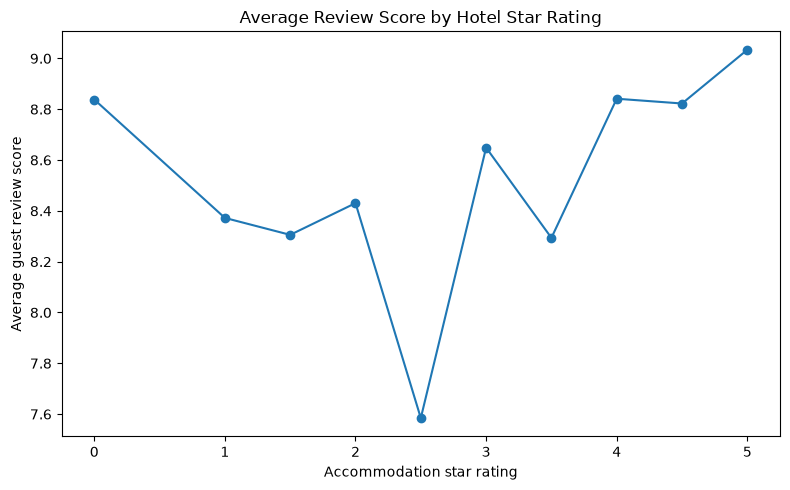

In [48]:
# Segment review outcomes by accommodation star rating
star_summary = (
    df_clean.groupby("accommodation_star_rating", dropna=False)
    .agg(
        review_count=("review_score", "count"),
        average_rating=("review_score", "mean"),
        low_rating_rate=("review_score", lambda x: x.dropna().le(5).mean() * 100)
    )
    .reset_index()
    .sort_values("accommodation_star_rating")
)

display(star_summary.round(2))

plt.figure(figsize=(8, 5))
plt.plot(
    star_summary["accommodation_star_rating"],
    star_summary["average_rating"],
    marker="o"
)
plt.xlabel("Accommodation star rating")
plt.ylabel("Average guest review score")
plt.title("Average Review Score by Hotel Star Rating")
plt.tight_layout()
plt.show()


In [65]:
# Segment review outcomes by guest type
guest_summary = (
    df_clean.groupby("guest_type", dropna=False)
    .agg(
        review_count=("review_score", "count"),
        average_rating=("review_score", "mean"),
        low_rating_rate=("review_score", lambda x: x.dropna().le(5).mean() * 100)
    )
    .reset_index()
    .sort_values("low_rating_rate", ascending=False)
)

display(guest_summary.round(2))


,guest_type,review_count,average_rating,low_rating_rate
3,Solo traveller,161671,8.66,1.11
1,Family with children,253104,8.73,1.09
2,Group,106818,8.78,0.82
0,Couple,400523,8.79,0.69


## Anomaly Detection with Isolation Forest

Isolation Forest is used as a screening method to identify reviews whose semantic representations are unusual relative to the modelling sample. An anomaly is not automatically a serious complaint or a confirmed operational failure. Flagged and unflagged examples must be manually reviewed.

This implementation uses sentence embeddings and PCA to reduce their dimensions before fitting Isolation Forest. It uses the same `model_df` sample as BERTopic so that topic assignments, ratings and anomaly scores remain aligned.


In [66]:
# Generate sentence embeddings for the same BERTopic sample
from sentence_transformers import SentenceTransformer

embedding_model = SentenceTransformer("all-MiniLM-L6-v2")

document_embeddings = embedding_model.encode(
    model_df["review_negative"].tolist(),
    batch_size=64,
    show_progress_bar=True,
    convert_to_numpy=True
)

print("Embedding matrix shape:", document_embeddings.shape)
assert document_embeddings.shape[0] == len(model_df)


Batches: 100%|██████████| 469/469 [00:16<00:00, 27.95it/s]


Embedding matrix shape: (30000, 384)


In [51]:
# Reduce embedding dimensions before anomaly detection
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

n_components = min(50, document_embeddings.shape[1], len(document_embeddings) - 1)

pca = PCA(
    n_components=n_components,
    random_state=42
)

reduced_embeddings = pca.fit_transform(document_embeddings)

print("Reduced feature shape:", reduced_embeddings.shape)
print(
    "Cumulative explained variance:",
    round(pca.explained_variance_ratio_.sum(), 4)
)


Reduced feature shape: (30000, 50)
Cumulative explained variance: 0.6519


In [67]:
# Fit Isolation Forest
from sklearn.ensemble import IsolationForest

# Contamination is an assumed expected fraction of unusual observations
# 0.02 is a screening choice, not a known true anomaly rate
isolation_forest = IsolationForest(
    n_estimators=200,
    contamination=0.02,
    random_state=42,
    n_jobs=-1
)

anomaly_labels = isolation_forest.fit_predict(reduced_embeddings)

# decision_function: lower values are more unusual
# Convert to anomaly_score so higher values indicate greater unusualness
decision_scores = isolation_forest.decision_function(reduced_embeddings)

model_df["anomaly_label"] = anomaly_labels
model_df["anomaly_score"] = -decision_scores
model_df["is_anomaly"] = model_df["anomaly_label"].eq(-1)

print("Anomalies flagged:", int(model_df["is_anomaly"].sum()))
print("Anomaly percentage:", round(model_df["is_anomaly"].mean() * 100, 2), "%")
display(
    model_df["is_anomaly"].value_counts()
    .rename(index={False: "Regular", True: "Flagged"})
    .to_frame("review_count")
)


Anomalies flagged: 600
Anomaly percentage: 2.0 %


,review_count
is_anomaly,
Regular,29400
Flagged,600


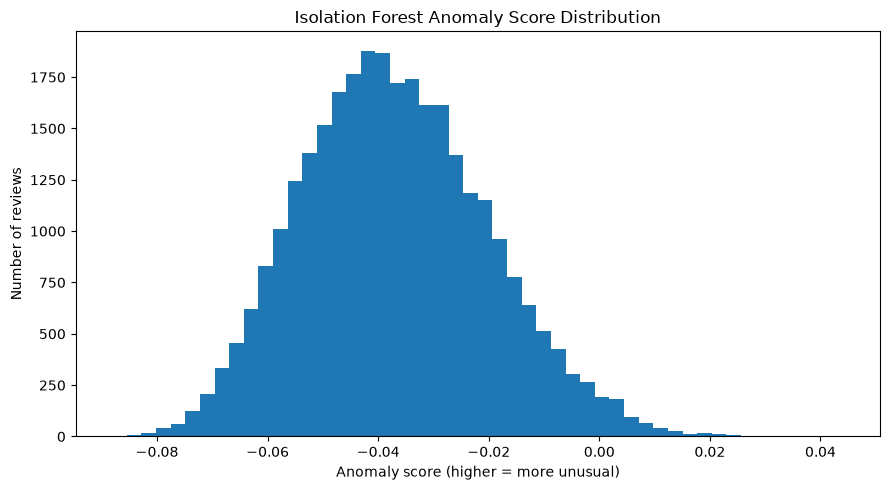

,is_anomaly,review_count,average_rating,low_rating_rate,average_anomaly_score
0,False,29400,8.42,1.32,-0.04
1,True,600,8.82,0.50,0.01


In [68]:
# Visualise anomaly-score distribution
plt.figure(figsize=(9, 5))
plt.hist(model_df["anomaly_score"], bins=50)
plt.xlabel("Anomaly score (higher = more unusual)")
plt.ylabel("Number of reviews")
plt.title("Isolation Forest Anomaly Score Distribution")
plt.tight_layout()
plt.show()

# Compare rating outcomes for flagged versus unflagged reviews
anomaly_profile = (
    model_df.groupby("is_anomaly")
    .agg(
        review_count=("review_score", "count"),
        average_rating=("review_score", "mean"),
        low_rating_rate=("review_score", lambda x: x.dropna().le(5).mean() * 100),
        average_anomaly_score=("anomaly_score", "mean")
    )
    .reset_index()
)

display(anomaly_profile.round(2))


In [69]:
# Inspect flagged reviews and a matched-size sample of unflagged reviews
review_columns = [
    "review_score", "room_nights", "guest_country",
    "topic", "topic_label", "anomaly_score", "review_negative"
]

flagged_reviews = model_df.loc[
    model_df["is_anomaly"], review_columns
].sort_values("anomaly_score", ascending=False)

regular_reviews = model_df.loc[
    ~model_df["is_anomaly"], review_columns
]

print("Highest-scoring unusual reviews:")
display(flagged_reviews.head(20))

print("\nRandom sample of unflagged reviews:")
display(
    regular_reviews.sample(
        min(20, len(regular_reviews)),
        random_state=42
    )
)


Highest-scoring unusual reviews:


,review_score,room_nights,guest_country,topic,topic_label,anomaly_score,review_negative
12032,9.0,2,Heyuru,1,Coffee and room-related experiences,0.044150,Even a very small refrigerator would be great...
21028,10.0,2,Zuc,17,Pillows,0.033368,"Pillow too high (as I am a small person), so always a problem"
7393,9.0,1,Mejok,18,Room lighting,0.029912,"Very minor, but there was a fire alarm right above one of the twin beds, and the light from it was quite strong. Probably not a problem for most, but a bit difficult for a light sleeper like me as I need complete pitch black."
27916,10.0,4,Fuxa,-1,Unassigned / outlier reviews,0.029228,A little small but it&#39;s okay!
1592,10.0,2,Nen,5,Staff and check-in,0.028250,staff are very good and helpful
15851,7.0,3,Casi,1,Coffee and room-related experiences,0.027514,Maybe a little mini fridge would be nice
26310,10.0,2,Cej,5,Staff and check-in,0.026942,"kinda hard to locate, but the staff are super helpful and responsive."
5930,8.0,1,Mejok,16,Television and channels,0.025590,TV a bit too small. That&#39;s it.
1911,8.0,3,Mejok,1,Coffee and room-related experiences,0.025280,"The only that would have been very useful, would have been a mini fridge."
26833,10.0,2,Fanir,16,Television and channels,0.025261,Wish there was NETFLIX installed on tv so we could use our accounts to watch something in the evenings.



Random sample of unflagged reviews:


,review_score,room_nights,guest_country,topic,topic_label,anomaly_score,review_negative
22616,10.0,3,Wiz,7,Location and accessibility,-0.034006,"It&#39;s quite far from the center city of Pereira( (30 min by car), where you will find all the restaurants and coffee places."
11319,10.0,4,Jof,4,Room size and condition,-0.049891,The room was a little small
3174,10.0,4,Made,8,Pool and spa facilities,-0.037038,I would have loved to have a pool at our hotel
10156,7.0,1,Mejok,12,Beds and mattresses,-0.059986,Beds were extremely uncomfortable
12815,8.0,1,Mejok,2,Noise,-0.044750,The rooms are have no internal insulation - the noise of other residents as they enter&#47;leaving their rooms throughout the night.
11789,10.0,2,Jof,3,Positive or no-complaint expressions,-0.045169,Everything was great so nothing!
7054,7.0,3,Zuc,-1,Unassigned / outlier reviews,-0.062366,"Far too much Jazz played in the restaurant which spoiled my dining experiences at breakfast and dinner (purely personal I know, but I can&#39;t be the only guest who has a wider taste in music!). I think that the spa villas are expensive for what they are, very creaky floors, balcony has raised nail heads which are bad for feet and badly fitting doors...blew open in the wind even though it was locked"
27782,9.0,1,Vema,-1,Unassigned / outlier reviews,-0.064098,"The private shower and toilet we had was not as new and good as we expected, but the public toilets and showers are renovated and great!"
14220,9.0,2,Rawabe,6,Parking,-0.043291,Free Parking is limited and you might need to pay extra 5€ for additional parking.
15335,6.0,3,Nukeye,0,Breakfast and food,-0.051287,Would have appreciated more variety at breakfast during the days there.


### Manual anomaly validation

Review the flagged and unflagged examples above. Record whether each flagged review represents:

1. A rare but potentially meaningful operational issue.
2. An unusual description of a common issue.
3. An irrelevant, vague or poorly worded review.
4. A false positive that does not warrant operational follow-up.

A useful evaluation table should report the number manually reviewed, the number judged relevant for follow-up, and examples of both relevant and irrelevant flags. Do not call all flagged reviews confirmed exceptions.


## Integrated Exception Prioritisation

This section combines three different signals:

**Frequency:** how many reviews are assigned to a topic.
**Severity association:** how much the topic's low-rating rate exceeds the overall sample rate.
**Unusualness:** how many reviews in the topic were flagged by Isolation Forest.

These indicators should be viewed together, not collapsed into a single score without a defensible weighting scheme. The table below provides a transparent topic-level profile.


In [70]:
# Combine topic-level severity and anomaly prevalence
integrated_summary = (
    model_df.groupby(["topic", "topic_label"], dropna=False)
    .agg(
        review_count=("review_negative", "size"),
        average_rating=("review_score", "mean"),
        low_rating_rate=("review_score", lambda x: x.dropna().le(5).mean() * 100),
        flagged_anomalies=("is_anomaly", "sum"),
        anomaly_rate=("is_anomaly", lambda x: x.mean() * 100),
        mean_anomaly_score=("anomaly_score", "mean")
    )
    .reset_index()
)

integrated_summary["low_rating_delta_pp"] = (
    integrated_summary["low_rating_rate"] - overall_low_rate
)

integrated_summary["share_of_sample_pct"] = (
    integrated_summary["review_count"] / len(model_df) * 100
)

integrated_summary = integrated_summary.sort_values(
    ["low_rating_delta_pp", "review_count"],
    ascending=[False, False]
)

display(integrated_summary.round(2))


,topic,topic_label,review_count,average_rating,low_rating_rate,flagged_anomalies,anomaly_rate,mean_anomaly_score,low_rating_delta_pp,share_of_sample_pct
25,24,Insects and pests,126,7.75,6.35,1,0.79,-0.04,5.04,0.42
15,14,Odor,553,7.88,3.44,12,2.17,-0.03,2.13,1.84
6,5,Staff and check-in,1170,8.20,2.39,50,4.27,-0.03,1.09,3.90
0,-1,Unassigned / outlier reviews,7509,8.19,2.02,78,1.04,-0.04,0.72,25.03
20,19,Towels and linen,268,8.26,1.87,21,7.84,-0.02,0.56,0.89
5,4,Room size and condition,1239,8.12,1.69,14,1.13,-0.04,0.39,4.13
12,11,Elevators,866,8.45,1.62,34,3.93,-0.03,0.31,2.89
16,15,Wifi and internet,519,8.33,1.54,18,3.47,-0.03,0.23,1.73
17,16,Television and channels,333,8.44,1.50,33,9.91,-0.02,0.19,1.11
14,13,Bathroom and toilet facilities,572,8.33,1.40,3,0.52,-0.04,0.09,1.91


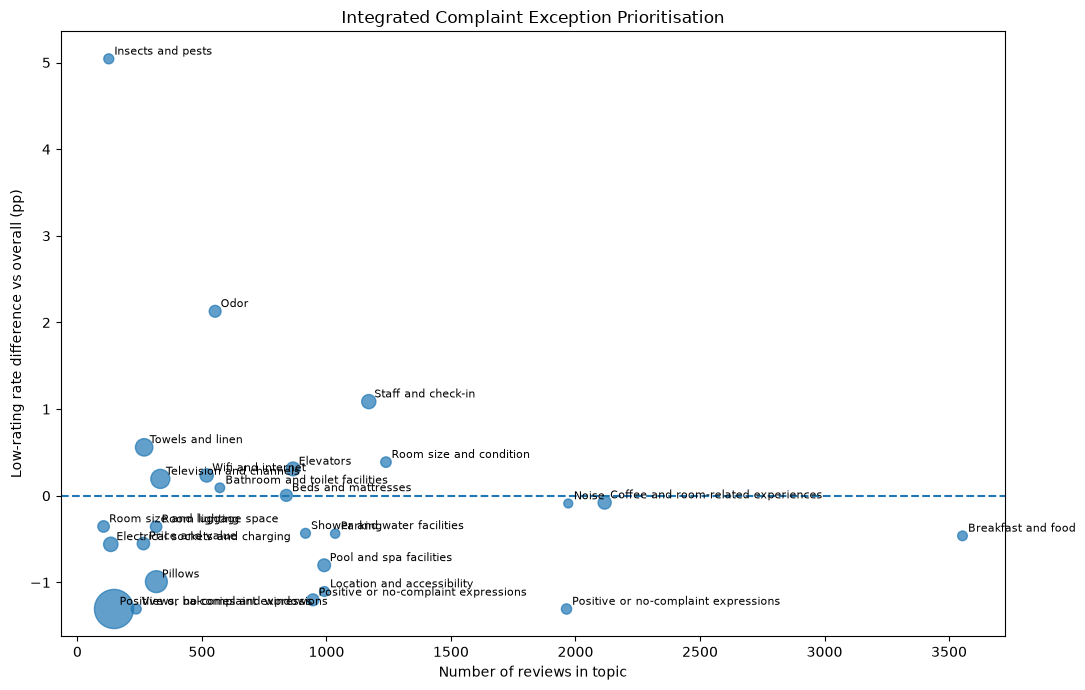

In [71]:
# Visual prioritisation: frequency versus severity, bubble size = anomaly rate
plot_integrated = integrated_summary[
    (integrated_summary["topic"] != -1)
    & (integrated_summary["review_count"] >= MIN_TOPIC_COUNT)
].copy()

plt.figure(figsize=(11, 7))
sizes = 40 + plot_integrated["anomaly_rate"].fillna(0) * 15

plt.scatter(
    plot_integrated["review_count"],
    plot_integrated["low_rating_delta_pp"],
    s=sizes,
    alpha=0.7
)

for _, row in plot_integrated.iterrows():
    plt.annotate(
        str(row["topic_label"]),
        (row["review_count"], row["low_rating_delta_pp"]),
        fontsize=8,
        xytext=(4, 3),
        textcoords="offset points"
    )

plt.axhline(0, linestyle="--")
plt.xlabel("Number of reviews in topic")
plt.ylabel("Low-rating rate difference vs overall (pp)")
plt.title("Integrated Complaint Exception Prioritisation")
plt.tight_layout()
plt.show()


### How to interpret the integrated prioritisation

- High volume and above-average low-rating prevalence: investigate as a potentially recurring and consequential issue.
- Low volume but high low-rating prevalence: inspect manually; the rate may be unstable because the topic is small.
- High anomaly prevalence: inspect unusual examples, but do not assume they are severe.
- High volume but below-average low-rating prevalence: common topic, not automatically a high-priority risk.

The analysis is exploratory and observational. It does not establish causation or confirm control failures.


## Evaluation and Limitations

Evaluate the work using a combination of quantitative checks and manual review:

**Topic discovery**
- Review topic sizes and outlier share.
- Check whether top terms and representative reviews support the assigned labels.
- Avoid forcing generic or mixed topics into specific operational categories.

**Anomaly detection**
- Manually inspect a sample of flagged reviews and a sample of unflagged reviews.
- Record how many flagged reviews appear relevant to further investigation.
- Recognise that Isolation Forest scores depend on the selected embeddings, PCA representation and contamination setting.

**Data and methodology limitations**
- The data are user-generated reviews and may contain selection bias.
- Keyword categories can miss synonyms, context and negation, and may generate false positives.
- Categories and topics can overlap.
- The BERTopic and anomaly-detection analyses use a sample of up to 30,000 negative reviews, not necessarily the entire dataset.
- Review score differences are associations, not evidence that a complaint caused the score.
- Anomaly detection identifies unusual patterns, not confirmed misconduct or operational failure.


In [72]:
# Final reproducibility and alignment checks
print("Rows in modelling sample:", len(model_df))
print("Topic assignments:", model_df["topic"].notna().sum())
print("Anomaly labels:", model_df["anomaly_label"].notna().sum())
print("Unique topic IDs:", model_df["topic"].nunique())
print("Flagged anomaly count:", int(model_df["is_anomaly"].sum()))

assert len(model_df) == len(cluster_data)
assert model_df["topic"].notna().all()
assert model_df["anomaly_label"].notna().all()

# Save the model-level review results for downstream checking/reporting.
model_df.to_csv("hotel_review_topic_anomaly_results.csv", index=False)
topic_summary.to_csv("hotel_review_topic_summary.csv", index=False)
integrated_summary.to_csv("hotel_review_exception_prioritisation.csv", index=False)

print("Exported modelling results and summary tables.")


Rows in modelling sample: 30000
Topic assignments: 30000
Anomaly labels: 30000
Unique topic IDs: 27
Flagged anomaly count: 600
Exported modelling results and summary tables.
